<a href="https://colab.research.google.com/github/saiwork2601-cmd/Alignment-of-satellite-using-AI-Agent/blob/main/alignment_py.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Maximum thruster torque: 0.014 Nm
Initial solar power: 86.60254037844388 W
Simulation completed!
PID final angle: -0.008 degrees
Agent final angle: -0.328 degrees


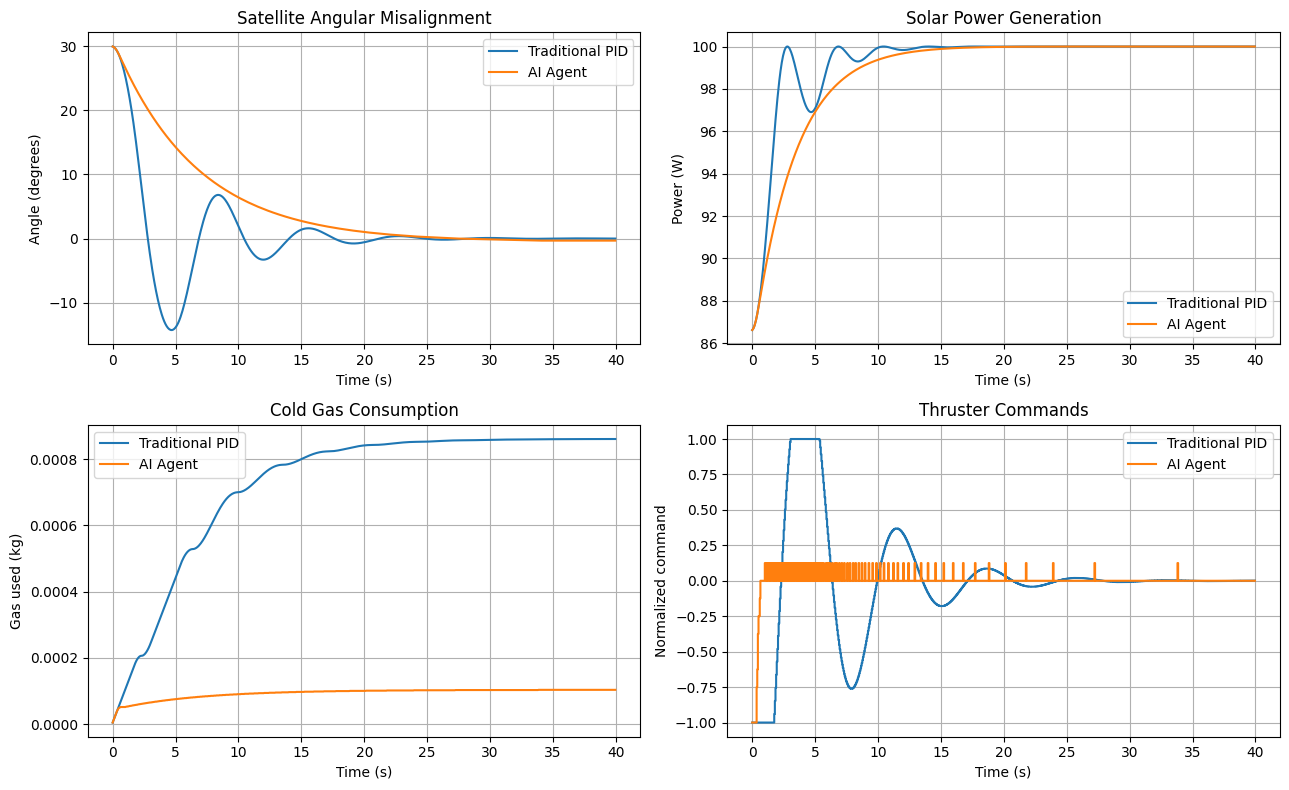

PERFORMANCE COMPARISON
----------------------

 Traditional PID
Final angular error: 0.008 degrees
Final solar power: 100.0 W
Solar energy captured: 3968.32 J
Gas consumed: 0.000861 kg

 AI Agent
Final angular error: 0.328 degrees
Final solar power: 100.0 W
Solar energy captured: 3948.74 J
Gas consumed: 0.000104 kg


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Satellite parameters
I = 0.1                 # Moment of inertia (kg m^2)
arm = 0.2               # Thruster lever arm (m)
mdot = 0.0001           # Gas flow rate (kg/s)
ve = 700                # Exhaust velocity (m/s)

MAX_TORQUE = arm * mdot * ve
INITIAL_GAS = 0.05      # Initial gas mass (kg)
MAX_POWER = 100         # Solar panel rated power (W)

dt = 0.05               # Simulation time step (s)
TOTAL_TIME = 40         # Simulation duration (s)

initial_angle = 30      # Initial misalignment (degrees)

print("Maximum thruster torque:", MAX_TORQUE, "Nm")
print("Initial solar power:",
      MAX_POWER * np.cos(np.radians(initial_angle)), "W")
def run_simulation(controller):

    theta = np.radians(initial_angle)
    omega = 0.0
    gas = INITIAL_GAS

    time_values = []
    angles = []
    powers = []
    gas_values = []
    commands = []

    kp = 0.08
    kd = 0.04

    for i in range(int(TOTAL_TIME / dt)):

        t = i * dt
        error = -theta

        if controller == "PID":

            # Traditional PID-style feedback controller
            u = (kp * error - kd * omega) / MAX_TORQUE
            u = np.clip(u, -1, 1)

        else:

            # AI agent: predict the outcome of candidate actions
            candidates = np.linspace(-1, 1, 17)
            scores = []

            horizon = 0.2

            for action in candidates:

                predicted_theta = theta
                predicted_omega = omega
                predicted_gas = gas

                for _ in range(int(horizon / dt)):

                    torque = action * MAX_TORQUE if predicted_gas > 0 else 0

                    predicted_omega += (torque / I) * dt
                    predicted_theta += predicted_omega * dt

                    predicted_gas = max(
                        0,
                        predicted_gas - mdot * abs(action) * dt
                    )

                gas_used = gas - predicted_gas

                cost = (
                    predicted_theta**2
                    + 0.8 * predicted_omega**2
                    + 0.001 * (gas_used / INITIAL_GAS)
                )

                scores.append(cost)

            u = candidates[np.argmin(scores)]

        # Safety: no gas means no thruster action
        if gas <= 0:
            u = 0

        # Apply the selected thruster command
        torque = u * MAX_TORQUE if gas > 0 else 0

        alpha = torque / I

        omega += alpha * dt
        theta += omega * dt

        gas = max(0, gas - mdot * abs(u) * dt)

        # Idealized solar power model
        power = MAX_POWER * max(0, np.cos(theta))

        time_values.append(t)
        angles.append(np.degrees(theta))
        powers.append(power)
        gas_values.append(gas)
        commands.append(u)

    return {
        "time": np.array(time_values),
        "angle": np.array(angles),
        "power": np.array(powers),
        "gas": np.array(gas_values),
        "command": np.array(commands)
    }

pid_result = run_simulation("PID")
agent_result = run_simulation("AGENT")

print("Simulation completed!")

print("PID final angle:",
   round(pid_result["angle"][-1], 3), "degrees")

print("Agent final angle:",
   round(agent_result["angle"][-1], 3), "degrees")
fig, ax = plt.subplots(2, 2, figsize=(13, 8))

# Angular misalignment
ax[0, 0].plot(pid_result["time"], pid_result["angle"],
              label="Traditional PID")
ax[0, 0].plot(agent_result["time"], agent_result["angle"],
              label="AI Agent")
ax[0, 0].set_title("Satellite Angular Misalignment")
ax[0, 0].set_xlabel("Time (s)")
ax[0, 0].set_ylabel("Angle (degrees)")
ax[0, 0].legend()
ax[0, 0].grid()

# Solar power
ax[0, 1].plot(pid_result["time"], pid_result["power"],
              label="Traditional PID")
ax[0, 1].plot(agent_result["time"], agent_result["power"],
              label="AI Agent")
ax[0, 1].set_title("Solar Power Generation")
ax[0, 1].set_xlabel("Time (s)")
ax[0, 1].set_ylabel("Power (W)")
ax[0, 1].legend()
ax[0, 1].grid()

# Gas consumption
ax[1, 0].plot(pid_result["time"],
              INITIAL_GAS - pid_result["gas"],
              label="Traditional PID")
ax[1, 0].plot(agent_result["time"],
              INITIAL_GAS - agent_result["gas"],
              label="AI Agent")
ax[1, 0].set_title("Cold Gas Consumption")
ax[1, 0].set_xlabel("Time (s)")
ax[1, 0].set_ylabel("Gas used (kg)")
ax[1, 0].legend()
ax[1, 0].grid()

# Thruster commands
ax[1, 1].step(pid_result["time"], pid_result["command"],
              label="Traditional PID")
ax[1, 1].step(agent_result["time"], agent_result["command"],
              label="AI Agent")
ax[1, 1].set_title("Thruster Commands")
ax[1, 1].set_xlabel("Time (s)")
ax[1, 1].set_ylabel("Normalized command")
ax[1, 1].legend()
ax[1, 1].grid()

plt.tight_layout()
plt.show()
def calculate_energy(result):
    return np.trapezoid(result["power"], result["time"])

print("PERFORMANCE COMPARISON")
print("----------------------")

for name, result in [
    ("Traditional PID", pid_result),
    ("AI Agent", agent_result)
]:

    energy = calculate_energy(result)
    gas_used = INITIAL_GAS - result["gas"][-1]
    final_error = abs(result["angle"][-1])

    print("\n", name)
    print("Final angular error:", round(final_error, 3), "degrees")
    print("Final solar power:", round(result["power"][-1], 2), "W")
    print("Solar energy captured:", round(energy, 2), "J")
    print("Gas consumed:", round(gas_used, 6), "kg")
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Circle, Rectangle
from IPython.display import HTML, display

result = agent_result

fig, ax = plt.subplots(figsize=(9, 5))
ax.set_xlim(-4, 5)
ax.set_ylim(-3, 3)
ax.set_aspect("equal")
ax.axis("off")

# Earth and Sun
earth = Circle((-3, 0), 1.0, color="royalblue")
ax.add_patch(earth)
ax.text(-3, -1.4, "EARTH", ha="center")

ax.scatter([4], [0], color="orange", s=400)
ax.text(4, -0.5, "SUN", ha="center")

# Satellite body
body = Rectangle((-0.35, -0.2), 0.7, 0.4,
                 color="gray", zorder=3)
ax.add_patch(body)

panel, = ax.plot([], [], linewidth=7, color="deepskyblue")
normal, = ax.plot([], [], color="orange", linewidth=2)
status = ax.text(0, 2.3, "", ha="center", fontsize=11)

def update(frame):

    angle = np.radians(result["angle"][frame])

    # Rotate the satellite body
    body.set_xy((-0.35, -0.2))
    from matplotlib.transforms import Affine2D
    body.set_transform(
        Affine2D().rotate_around(0, 0, angle) + ax.transData
    )

    # Draw solar panel perpendicular to its normal
    nx, ny = np.cos(angle), np.sin(angle)
    px, py = -ny, nx

    panel.set_data(
        [-0.5*px, 0.5*px],
        [-0.5*py, 0.5*py]
    )

    normal.set_data([0, nx], [0, ny])

    status.set_text(
        f"Time: {result['time'][frame]:.1f} s | "
        f"Misalignment: {result['angle'][frame]:.2f}° | "
        f"Power: {result['power'][frame]:.1f} W"
    )

    return body, panel, normal, status

ani = FuncAnimation(
    fig, update,
    frames=range(0, len(result["time"]), 4),
    interval=50,
    blit=False
)

display(HTML(ani.to_jshtml()))
plt.close(fig)